# 05 · Final model evaluation

Notebooks 02–04 chose the model; this notebook checks the **production code** (`src/`) that will be shipped:
1. Fit `FraudModel` (exactly what `src/train.py` runs) on the 80k dev rows and score the untouched 20k holdout,
   reproducing notebook 04's numbers through the real pipeline.
2. **How sure are we?** Bootstrap 95% confidence intervals on the holdout and *paired* bootstrap comparisons against
   the baseline, the untuned model and the leaky model.
3. **How would the bank use it?** Operating points: alerts, precision and recall at different thresholds.
4. **Calibration**: do predicted probabilities match observed mule rates?
5. **Leakage follow-up** on the most closure-correlated feature kept (`others_25`).
6. **External sanity check** on the validation file.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, confusion_matrix, average_precision_score, log_loss
from src.data import DataLoader, ID, TARGET
from src.features import FeatureBuilder, COUNTERS
from src.model import FraudModel, XGBCV, PlattCalibrator, evaluate
from src.train import XGB_TUNED, WEIGHT_POWER

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.float_format', '{:.4f}'.format, 'display.width', 200)

train = DataLoader().load('train')
y = train[TARGET]
idx_dev, idx_hold = train_test_split(train.index, test_size=.2, stratify=y, random_state=42)   # same split as 02–04
dev, hold = train.loc[idx_dev], train.loc[idx_hold]
y_dev, y_hold = y.loc[idx_dev].values, y.loc[idx_hold].values

## 1. Production pipeline on the holdout

In [2]:
final = FraudModel(XGB_TUNED, WEIGHT_POWER).fit(dev)          # raw frame in, P(mule) out
p_final = final.predict_proba(hold)
print(f'mule weight {final.cv_.pos_weight_:.2f} | best rounds per fold {final.cv_.best_iters_}')
pd.DataFrame({'OOF (dev)': evaluate(y_dev, final.oof_), 'holdout': evaluate(y_hold, p_final)}).T

mule weight 2.28 | best rounds per fold [623, 795, 719, 438, 699]


,roc_auc,pr_auc,log_loss,brier
OOF (dev),0.9969,0.9497,0.0128,0.0032
holdout,0.9975,0.9529,0.0125,0.0032


**Comparators**, trained the same way (5-fold CV on dev, Platt on OOF, same seed):
* *leak-free baseline*: notebook 02's raw data minus the counters, default params, weight ×49;
* *untuned*: final features, default params, no weight (the best untuned setting in notebook 04);
* *leaky*: final model + the 9 counters and their shortfall features (what the leak would have bought).

In [3]:
def cv_predict(Xd, Xh, **kw):
    cv = XGBCV(seed=42, **kw).fit(Xd, y_dev)
    cal = PlattCalibrator().fit(cv.oof_, y_dev)
    return cal.predict(cv.predict_proba(Xh))

def to_raw(df):
    X = df.drop(columns=[ID, TARGET, *COUNTERS], errors='ignore')
    X['account_opening_date'] = X.account_opening_date.astype('int64') // 86_400_000_000
    for c in X.select_dtypes(exclude='number').columns:
        X[c] = X[c].astype('category')
    return X

fb = FeatureBuilder().fit(dev)
F_dev, F_hold = fb.transform(dev), fb.transform(hold)
raw = to_raw(train)
leaky = lambda F, df: F.assign(**{c: df[c] for c in COUNTERS}, **{f'short_{c}': F.account_age - df[c] for c in COUNTERS})
P = {'final (tuned XGBoost)': p_final,
     'leak-free baseline (nb 02)': cv_predict(raw.loc[idx_dev], raw.loc[idx_hold], weight_power=1),
     'untuned, no weight': cv_predict(F_dev, F_hold, weight_power=0),
     'leaky (final + counters)': cv_predict(leaky(F_dev, dev), leaky(F_hold, hold), params=XGB_TUNED, weight_power=WEIGHT_POWER)}
pd.DataFrame({k: evaluate(y_hold, v) for k, v in P.items()}).T

,roc_auc,pr_auc,log_loss,brier
final (tuned XGBoost),0.9975,0.9529,0.0125,0.0032
leak-free baseline (nb 02),0.9932,0.9288,0.0164,0.0038
"untuned, no weight",0.9977,0.9569,0.0123,0.0032
leaky (final + counters),0.9994,0.9760,0.0086,0.0024


## 2. How sure are we? Bootstrap confidence intervals
The holdout has only 400 mules, so every metric is uncertain. Resampling the holdout rows with replacement 2,000 times
gives 95% intervals. **Paired** comparisons resample the *same* rows for both models, so they measure the uncertainty of
the *difference*, which is much tighter than comparing two separate intervals.

In [4]:
rng = np.random.default_rng(0)
B = [rng.integers(0, len(y_hold), len(y_hold)) for _ in range(2000)]
ll = lambda yy, p: log_loss(yy, p, labels=[0, 1])

ci = {}
for k, p in P.items():
    s = pd.DataFrame([{'log_loss': ll(y_hold[i], p[i]), 'pr_auc': average_precision_score(y_hold[i], p[i])} for i in B])
    ci[k] = {f'{m} {q}': s[m].quantile(qv) for m in s for q, qv in [('2.5%', .025), ('97.5%', .975)]}
pd.DataFrame(ci).T

,log_loss 2.5%,log_loss 97.5%,pr_auc 2.5%,pr_auc 97.5%
final (tuned XGBoost),0.0103,0.0151,0.9361,0.9672
leak-free baseline (nb 02),0.0135,0.0195,0.9057,0.9485
"untuned, no weight",0.0102,0.0146,0.9420,0.9703
leaky (final + counters),0.0068,0.0105,0.9659,0.9846


In [5]:
rows = {}
for k in list(P)[1:]:
    d = pd.DataFrame([{'Δ log-loss (final − other)': ll(y_hold[i], P['final (tuned XGBoost)'][i]) - ll(y_hold[i], P[k][i]),
                       'Δ PR-AUC (final − other)': average_precision_score(y_hold[i], P['final (tuned XGBoost)'][i]) - average_precision_score(y_hold[i], P[k][i])}
                      for i in B])
    rows[k] = {**{f'{m} mean': d[m].mean() for m in d}, **{f'{m} 95% CI': f'[{d[m].quantile(.025):+.4f}, {d[m].quantile(.975):+.4f}]' for m in d},
               'P(final has lower log-loss)': (d.iloc[:, 0] < 0).mean()}
pd.DataFrame(rows).T

,Δ log-loss (final − other) mean,Δ PR-AUC (final − other) mean,Δ log-loss (final − other) 95% CI,Δ PR-AUC (final − other) 95% CI,P(final has lower log-loss)
leak-free baseline (nb 02),-0.0038,0.0241,"[-0.0051, -0.0026]","[+0.0150, +0.0344]",1.0000
"untuned, no weight",0.0003,-0.0041,"[-0.0003, +0.0009]","[-0.0087, +0.0003]",0.1785
leaky (final + counters),0.0039,-0.0232,"[+0.0025, +0.0055]","[-0.0341, -0.0139]",0.0000


## 3. Operating points: how would the bank use the scores?
The model outputs a probability; the bank chooses a threshold that matches its investigation capacity. Thresholds
are evaluated on the holdout. The F1-optimal threshold is chosen on the **dev OOF** predictions, not on the holdout.

In [6]:
pr, rc, thr = precision_recall_curve(y_dev, final.oof_)
t_f1 = thr[np.argmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))]
ops = []
for t in [.02, .05, .1, .2, t_f1, .5, .8, .95]:
    flag = p_final >= t
    tp = (flag & (y_hold == 1)).sum()
    ops.append({'threshold': t, 'alerts per 10k accounts': flag.mean() * 1e4, 'precision': tp / max(flag.sum(), 1),
                'recall': tp / (y_hold == 1).sum(), 'mules caught': tp, 'false alarms': (flag & (y_hold == 0)).sum(),
                'note': 'F1-optimal (chosen on dev OOF)' if t == t_f1 else ''})
pd.DataFrame(ops).round(4)

,threshold,alerts per 10k accounts,precision,recall,mules caught,false alarms,note
0,0.0200,369.0000,0.5285,0.9750,390,348,
1,0.0500,276.5000,0.6908,0.9550,382,171,
2,0.1000,244.5000,0.7730,0.9450,378,111,
3,0.2000,214.0000,0.8551,0.9150,366,62,
4,0.4112,187.5000,0.9253,0.8675,347,28,F1-optimal (chosen on dev OOF)
5,0.5000,181.5000,0.9394,0.8525,341,22,
6,0.8000,152.5000,0.9836,0.7500,300,5,
7,0.9500,118.0000,0.9915,0.5850,234,2,


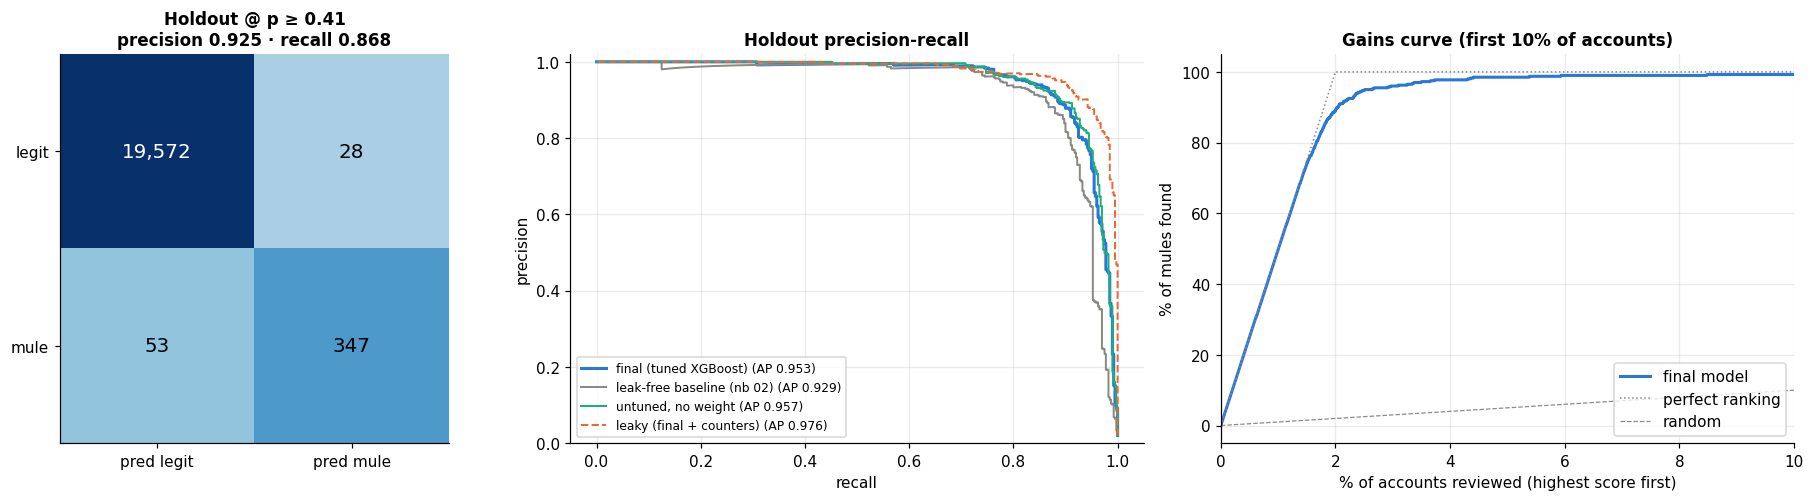

reviewing the top 2% of accounts finds 89.0% of mules


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1, 1.2, 1.2]})
cm = confusion_matrix(y_hold, p_final >= t_f1)
axes[0].imshow(cm, cmap='Blues', norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=len(y_hold))); axes[0].grid(False)
for (i, j), v in np.ndenumerate(cm):
    axes[0].text(j, i, f'{v:,}', ha='center', va='center', fontsize=13, color='white' if v > 1000 else 'black')
tn, fp, fn, tp = cm.ravel()
axes[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=['pred legit', 'pred mule'], yticklabels=['legit', 'mule'],
            title=f'Holdout @ p ≥ {t_f1:.2f}\nprecision {tp / (tp + fp):.3f} · recall {tp / (tp + fn):.3f}')
for (k, p), col in zip(P.items(), [BLUE, GRAY, AQUA, ORANGE]):
    a, b, _ = precision_recall_curve(y_hold, p)
    axes[1].plot(b, a, color=col, lw=2 if k.startswith('final') else 1.3, ls='-' if not k.startswith('leaky') else '--',
                 label=f'{k} (AP {average_precision_score(y_hold, p):.3f})')
axes[1].set(xlabel='recall', ylabel='precision', ylim=(0, 1.02), title='Holdout precision-recall'); axes[1].legend(fontsize=8, loc='lower left')
order = np.argsort(-p_final)
k_pct = np.arange(1, len(order) + 1) / len(order) * 100
axes[2].plot(k_pct, np.cumsum(y_hold[order]) / y_hold.sum() * 100, color=BLUE, lw=2, label='final model')
axes[2].plot([0, 2, 100], [0, 100, 100], color=GRAY, ls=':', lw=1, label='perfect ranking')
axes[2].plot([0, 100], [0, 100], color=GRAY, ls='--', lw=.8, label='random')
axes[2].set(xlim=(0, 10), xlabel='% of accounts reviewed (highest score first)', ylabel='% of mules found', title='Gains curve (first 10% of accounts)')
axes[2].legend(loc='lower right'); plt.tight_layout(); plt.show()
print(f'reviewing the top 2% of accounts finds {np.cumsum(y_hold[order])[int(.02 * len(order)) - 1] / y_hold.sum():.1%} of mules')

## 4. Calibration: are the probabilities honest?
The case study scores probability accuracy, so a predicted 30% should mean ~30% of such accounts are mules.

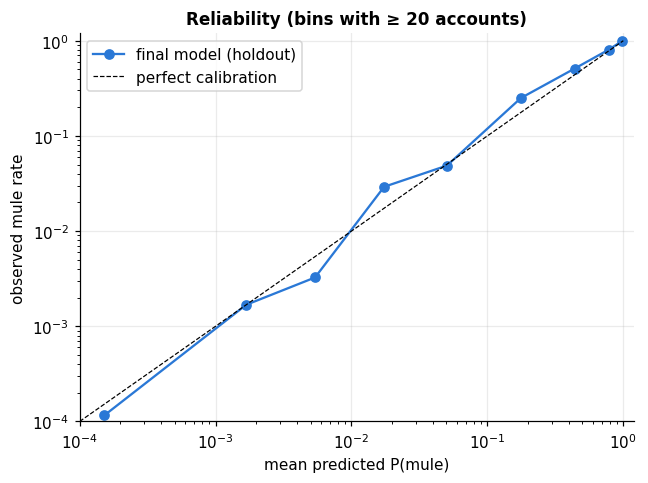

mean predicted 0.0192 vs observed 0.0200


,accounts,mean_predicted,observed_rate,mules
bin,,,,
"(-0.001, 0.001]",17271,0.0002,0.0001,2
"(0.001, 0.003]",1188,0.0017,0.0017,2
"(0.003, 0.01]",614,0.0054,0.0033,2
"(0.01, 0.03]",274,0.0174,0.0292,8
"(0.03, 0.1]",164,0.0504,0.0488,8
"(0.1, 0.3]",92,0.1764,0.2500,23
"(0.3, 0.6]",49,0.4389,0.5102,25
"(0.6, 0.9]",82,0.7810,0.8049,66
"(0.9, 1.0]",266,0.9790,0.9925,264


In [8]:
edges = [0, .001, .003, .01, .03, .1, .3, .6, .9, 1]
cal_tab = pd.DataFrame({'p': p_final, 'y': y_hold, 'bin': pd.cut(p_final, edges, include_lowest=True)}) \
    .groupby('bin', observed=True).agg(accounts=('y', 'size'), mean_predicted=('p', 'mean'), observed_rate=('y', 'mean'), mules=('y', 'sum'))
fig, ax = plt.subplots(figsize=(6, 4.5))
ok = cal_tab[cal_tab.accounts >= 20]
ax.plot(ok.mean_predicted, ok.observed_rate, 'o-', color=BLUE, ms=6, lw=1.5, label='final model (holdout)')
ax.plot([1e-4, 1], [1e-4, 1], ls='--', color='black', lw=.8, label='perfect calibration')
ax.set(xscale='log', yscale='log', xlim=(1e-4, 1.2), ylim=(1e-4, 1.2), xlabel='mean predicted P(mule)', ylabel='observed mule rate',
       title='Reliability (bins with ≥ 20 accounts)'); ax.legend(); plt.tight_layout(); plt.show()
print(f'mean predicted {p_final.mean():.4f} vs observed {y_hold.mean():.4f}')
cal_tab

## 5. Leakage follow-up: is `others_25` leaky?
It is the kept feature most associated with closure (AUC 0.67 among legit accounts, notebook 04 section 7). If the
freeze *mechanically* changed it (e.g. a frozen account cannot log in), closed accounts would show **lower** values.

In [9]:
closed = (FeatureBuilder().fit(train).transform(train).account_age - train.others_13) > 0
rows = {}
for c in ['others_25', 'others_21', 'others_26', 'txn_80', 'txn_78']:
    rows[c] = {'legit, open: median': train.loc[(y == 0) & ~closed, c].median(), 'legit, closed: median': train.loc[(y == 0) & closed, c].median(),
               'mules: median': train.loc[y == 1, c].median()}
pd.DataFrame(rows).T

,"legit, open: median","legit, closed: median",mules: median
others_25,1.0000,7.0000,32.0000
others_21,1.0000,7.0000,21.0000
others_26,5.0000,19.0000,49.0000
txn_80,5.0000,6.0000,35.0000
txn_78,4.0000,4.0000,0.0000


## 6. External sanity check on the validation file (inferred labels)
The development file is sorted by target (all mules are the last 2% of rows, EDA section 4). If the 50k validation file
was built the same way, its **last 1,000 rows** (exactly 2%) would be the mules. The model never sees row order, so
if its high scores pile up in those rows, that is independent confirmation. Those inferred labels then give an
**external** estimate of performance. This is an *assumption* used only for this sanity check, never for training
or model selection. The model scored here is the same dev-trained model as above.

rows 1–49,000: mean P 0.0034, P≥0.5: 88 | last 1,000 rows: mean P 0.841, P≥0.5: 881


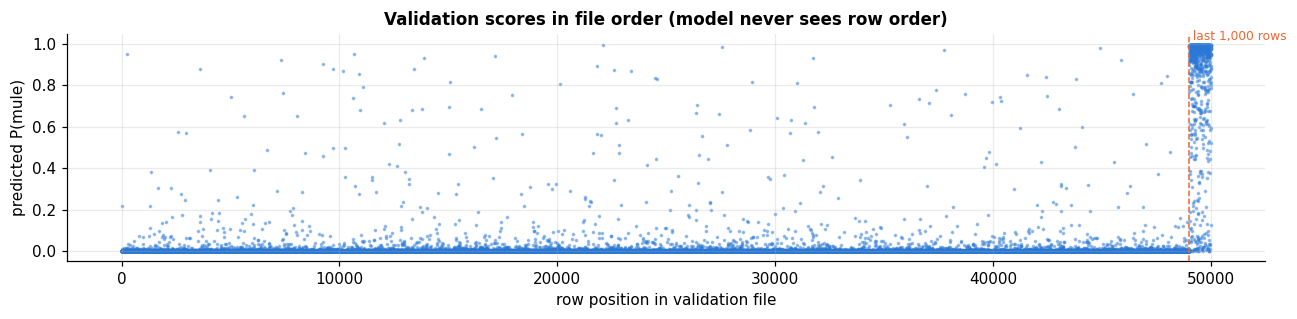

,roc_auc,pr_auc,log_loss,brier
holdout (true labels),0.9975,0.9529,0.0125,0.0032
validation (inferred labels),0.9963,0.9459,0.0133,0.0033


In [10]:
valid = DataLoader().load('validation')
p_val = final.predict_proba(valid)
pos = np.arange(len(valid)) >= len(valid) - 1000
print(f'rows 1–49,000: mean P {p_val[~pos].mean():.4f}, P≥0.5: {(p_val[~pos] >= .5).sum()} | last 1,000 rows: mean P {p_val[pos].mean():.3f}, P≥0.5: {(p_val[pos] >= .5).sum()}')
fig, ax = plt.subplots(figsize=(12, 3))
ax.scatter(np.arange(len(p_val)), p_val, s=2, color=BLUE, alpha=.4, rasterized=True)
ax.axvline(len(valid) - 1000, color=ORANGE, ls='--', lw=1); ax.text(len(valid) - 1000, 1.02, ' last 1,000 rows', color=ORANGE, fontsize=8)
ax.set(xlabel='row position in validation file', ylabel='predicted P(mule)', title='Validation scores in file order (model never sees row order)')
plt.tight_layout(); plt.show()
pd.DataFrame({'holdout (true labels)': evaluate(y_hold, p_final), 'validation (inferred labels)': evaluate(pos.astype(int), p_val)}).T

## 7. Summary

* **The shipped pipeline reproduces the experiments**: `FraudModel` (= `src/train.py`) scores holdout ROC-AUC 0.9975 ·
  PR-AUC 0.953 · log-loss 0.0125 · Brier 0.0032, matching notebook 04.
* **Uncertainty (95% bootstrap CI, holdout):** log-loss 0.0103–0.0151, PR-AUC 0.936–0.967.
* **vs the leak-free baseline:** log-loss −0.0038 [−0.0051, −0.0026], PR-AUC +0.024 [+0.015, +0.034], a clear,
  significant improvement (better in 100% of bootstrap samples).
* **vs untuned / unweighted XGBoost:** statistically **tied** on the holdout (Δ log-loss +0.0003, CI [−0.0003, +0.0009]).
  The tuned model won on OOF (0.0129 vs 0.0138, 3 seeds). That OOF gap is partly optimistic because Optuna searched on
  the same dev rows, and the holdout cannot separate the two. The model was **not** re-selected on the holdout: choosing
  on the test set would turn it into a validation set and void the unbiased estimate. Both are valid choices.
* **vs the leaky model:** the leak would have bought −0.0039 log-loss and +0.023 PR-AUC. That is the honest cost of a
  model that works on live, still-open accounts.
* **Operating points** (holdout, 20k accounts): at the F1-optimal threshold (0.41, chosen on dev OOF) **347 of 400 mules
  are caught with 28 false alarms** (precision 92.5%, recall 86.8%). Reviewing the top 2% of accounts finds 89% of
  mules; a lower threshold (0.1) reaches 94.5% recall at 77% precision. The bank picks the point that fits its
  investigation capacity.
* **Calibration:** mean predicted 1.92% vs observed 2.00%; predicted and observed rates agree across the probability
  range (slight under-prediction in the 10–30% bin, 92 accounts).
* **Leakage follow-up:** closed legit accounts have *more* logins than open ones (median 7 vs 1). A freeze cannot
  create logins, so `others_25` reflects who gets closed (active accounts), not the closure itself. It stays.
* **External sanity check:** the validation file appears to be sorted like the development file. The model, which
  never sees row order, puts 881 of its 969 scores ≥ 0.5 into the last 1,000 rows (exactly 2%). Treating those rows as
  *inferred* labels gives ROC-AUC 0.996 · PR-AUC 0.946 · log-loss 0.0133 on 50k unseen accounts, consistent with the
  holdout. (An assumption used only as a sanity check, never for training or selection.)